# Step 6 — Eteroschedasticità e dinamiche della volatilità

Studiamo le innovazioni dei modelli della media selezionati nello [step 5](../step5/dataset_ethereum.ipynb). ARCH, autocorrelazione dei quadrati e previsioni della varianza distinguono clustering, dipendenza dallo stato e utilità predittiva.

La finestra è la stessa dello step 5: i residui validation servono alla stima della varianza, quelli testing alla misura fuori campione. I modelli gaussiani sono diagnostici, non un generatore dell’utilizzo, che deve restare in [0, 2].

**Risultato osservato:** emergono segnali ARCH per X, log p50 e dispersione, mentre non emergono per log p90 in questa finestra. GJR migliora il fit validation ma non sempre il QLIKE testing; alcuni residui standardizzati restano dipendenti. Dettagli nei [findings](findings.md).

## 1. Modelli iniziali della media e allineamento

Ricarichiamo i residui delle medie autoregressive dello step 5 senza ristimare sul testing.
Controlliamo blocchi, ruoli e ordine temporale per collegare correttamente gli stati osservabili alle innovazioni.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/CONTEXT.md").is_file()
)
source = project_root / "outputs/notebook_diagnostics/ethereum/step1"
summary = json.loads((source / "preprocessing_summary.json").read_text())
assert summary["chain_id"] == 1
assert summary["dataset_id"] == "e7b17cfb-320d-4e6c-93c1-06dbc24f312d"
df = pd.read_parquet(source / "ethereum_blocks_diagnostics.parquet")
assert len(df) == summary["rows"]
assert np.all(np.diff(df["block_number"]) == 1)
output_directory = project_root / "outputs/notebook_diagnostics/ethereum/step6"
output_directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.figsize": (11, 4),
        "figure.dpi": 110,
        "font.size": 11,
        "axes.grid": True,
        "grid.alpha": 0.2,
    }
)
pd.set_option("display.max_rows", 24)
pd.set_option("display.max_columns", 12)
variables = {
    "X": "X",
    "log_p50": "log_effective_priority_fee_per_gas_p50",
    "log_p90": "log_effective_priority_fee_per_gas_p90",
    "dispersion": "priority_fee_dispersion",
}

step5 = output_directory.parent / "step5"
residuals = pd.read_parquet(step5 / "mean_residuals.parquet")
selected_lags = json.loads((step5 / "selected_lags.json").read_text())
scope = json.loads((step5 / "analysis_scope.json").read_text())
assert scope["dataset_id"] == summary["dataset_id"]
assert scope["dataset_sha256"] == summary["dataset_sha256"]
assert np.all(np.diff(residuals["block_number"]) == 1)
assert np.array_equal(
    residuals["timestamp"], df.set_index("block_number").loc[residuals.block_number, "timestamp"]
)
assert residuals.filter(like="residual_").notna().all().all()
assert set(residuals["role"]) == {"training", "validation", "testing"}
validation = residuals.query("role == 'validation'").copy()
testing = residuals.query("role == 'testing'").copy()
assert validation["block_number"].max() < testing["block_number"].min()
assert len(validation) == len(testing) == 5000
display(pd.Series(selected_lags, name="Lag della media, scelti sulla validation").to_frame())
display(
    pd.DataFrame(
        {
            "role": ["validation", "testing"],
            "first_block": [validation.block_number.min(), testing.block_number.min()],
            "last_block": [validation.block_number.max(), testing.block_number.max()],
        }
    )
)

,"Lag della media, scelti sulla validation"
X,10
log_p50,10
log_p90,10
dispersion,10


,role,first_block,last_block
0,validation,25580230,25585229
1,testing,25585230,25590229


## 2. Residui e residui al quadrato

Cerchiamo errori grandi e sequenze di errori grandi dopo la previsione della media.
I quadrati separano l’ampiezza dal segno; tutte le osservazioni mostrate appartengono al testing.

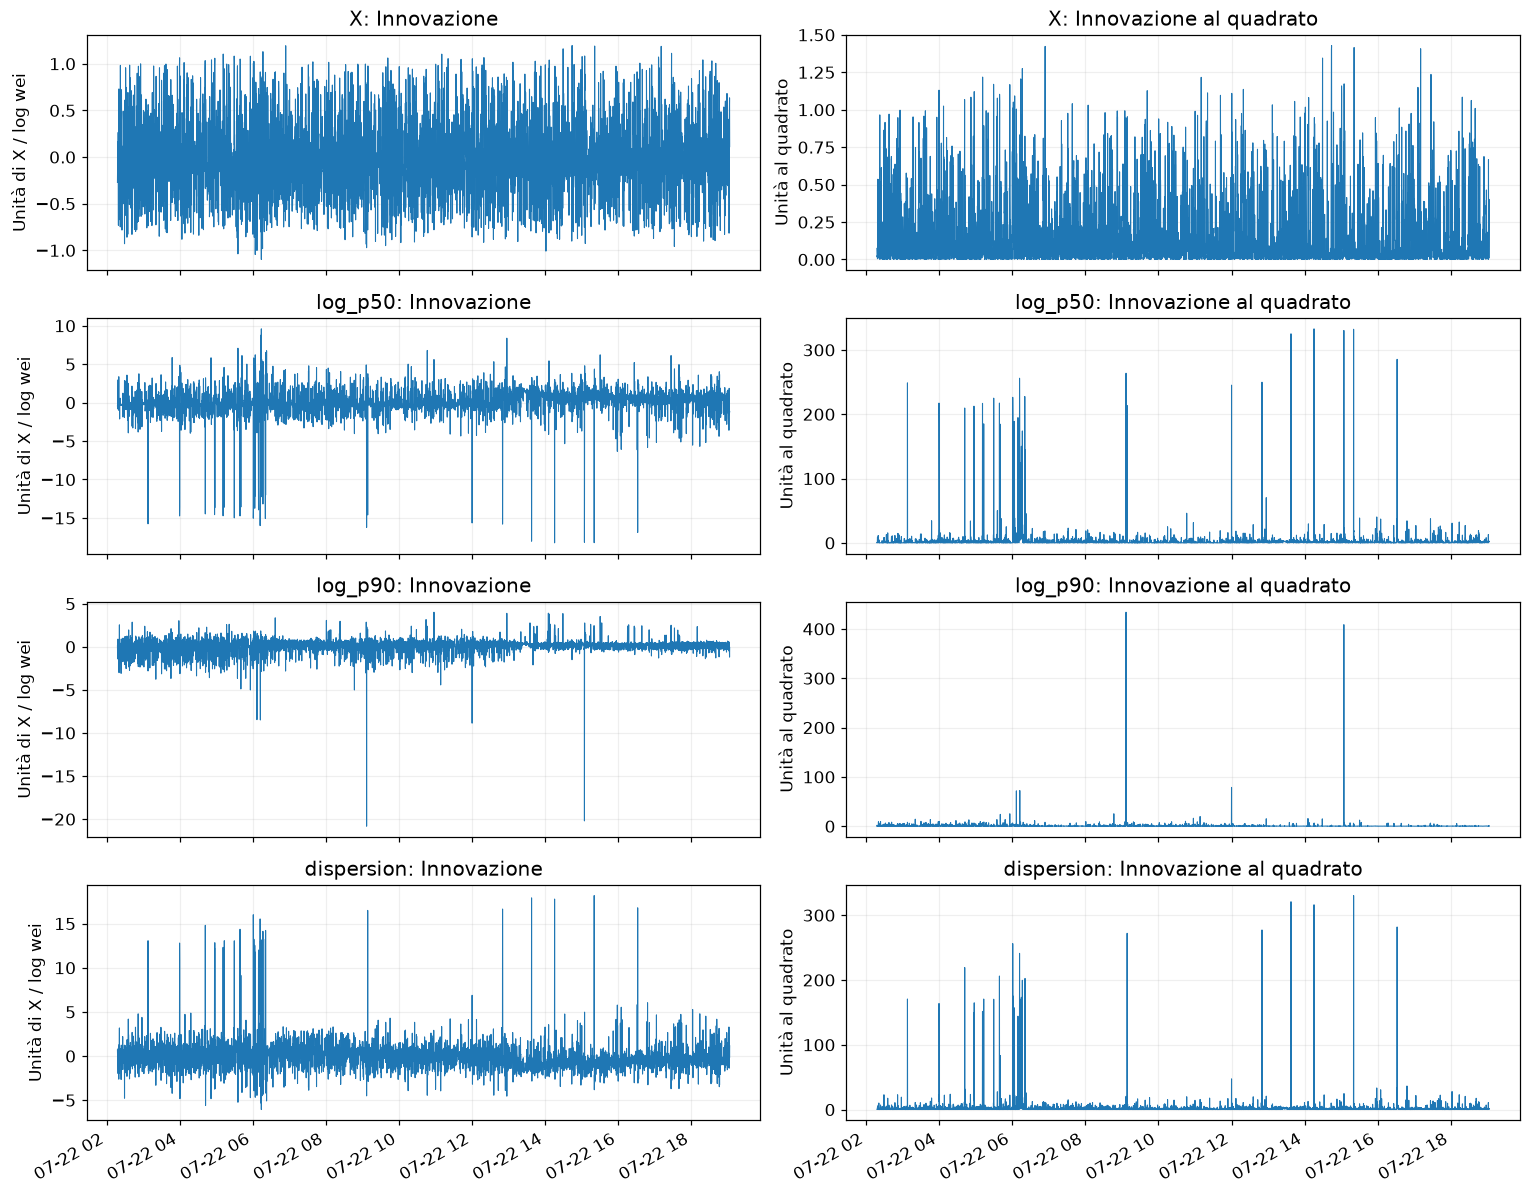

In [2]:
dates = pd.to_datetime(testing["timestamp"], unit="s", utc=True)
fig, axes = plt.subplots(4, 2, figsize=(14, 11), sharex=True)
for row, name in enumerate(variables):
    errors = testing[f"residual_{name}"]
    for col, (values, label) in enumerate(
        [(errors, "Innovazione"), (errors**2, "Innovazione al quadrato")]
    ):
        axes[row, col].plot(dates, values, linewidth=0.7)
        axes[row, col].set(
            title=f"{name}: {label}",
            ylabel="Unità di X / log wei" if col == 0 else "Unità al quadrato",
        )
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
plt.close(fig)

## 3. ARCH-LM

Verifichiamo se i lag dei residui al quadrato predicono la loro ampiezza corrente.
I test a 5, 10, 20 e 50 lag sono diagnostici e possono risentire della dinamica rimasta nella media.

In [3]:
arch_rows = []
squared_lb = []
for name in variables:
    errors = testing[f"residual_{name}"].to_numpy()
    for lag in [5, 10, 20, 50]:
        lm, pvalue, f_stat, f_pvalue = het_arch(errors, nlags=lag, ddof=0)
        arch_rows.append(
            {"variable": name, "lag": lag, "LM": lm, "LM_p": pvalue, "F": f_stat, "F_p": f_pvalue}
        )
    table = acorr_ljungbox(errors**2, lags=[5, 10, 20, 50], model_df=0, return_df=True)
    squared_lb.append(table.rename_axis("lag").reset_index().assign(variable=name))
arch_tests = pd.DataFrame(arch_rows)
squared_tests = pd.concat(squared_lb, ignore_index=True)
display(arch_tests.round(6))
arch_tests.to_csv(output_directory / "arch_lm.csv", index=False)
squared_tests.to_csv(output_directory / "squared_ljung_box.csv", index=False)

/Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/.venv/lib/python3.11/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
/Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/.venv/lib/python3.11/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result

,variable,lag,LM,LM_p,F,F_p
0,X,5,239.939373,0.000000,50.348781,0.000000
1,X,10,244.652576,0.000000,25.669884,0.000000
2,X,20,257.055288,0.000000,13.495152,0.000000
3,X,50,287.329221,0.000000,6.037852,0.000000
4,log_p50,5,221.450047,0.000000,46.289001,0.000000
5,log_p50,10,272.384827,0.000000,28.747662,0.000000
6,log_p50,20,293.700092,0.000000,15.539539,0.000000
7,log_p50,50,354.578740,0.000000,7.560052,0.000000
8,log_p90,5,2.927407,0.711177,0.585121,0.711451
9,log_p90,10,4.412148,0.926845,0.440632,0.927075


## 4. Ljung–Box sui quadrati

Verifichiamo congiuntamente le autocorrelazioni dei residui al quadrato a 5, 10, 20 e 50 lag.
Usiamo model_df=0 perché il testing non stima i coefficienti della media.

In [4]:
display(squared_tests.round(6))

,lag,lb_stat,lb_pvalue,variable
0,5,304.804094,0.000000,X
1,10,314.709117,0.000000,X
2,20,345.675163,0.000000,X
3,50,369.058633,0.000000,X
4,5,305.902089,0.000000,log_p50
5,10,467.733823,0.000000,log_p50
6,20,587.712005,0.000000,log_p50
7,50,779.273814,0.000000,log_p50
8,5,3.021239,0.696711,log_p90
9,10,4.626321,0.914703,log_p90


## 5. Volatilità mobile

Esaminiamo come cambia la deviazione standard delle innovazioni in finestre di 250 blocchi.
Una persistenza dei periodi più variabili è un segnale descrittivo di clustering, non un test di regime.

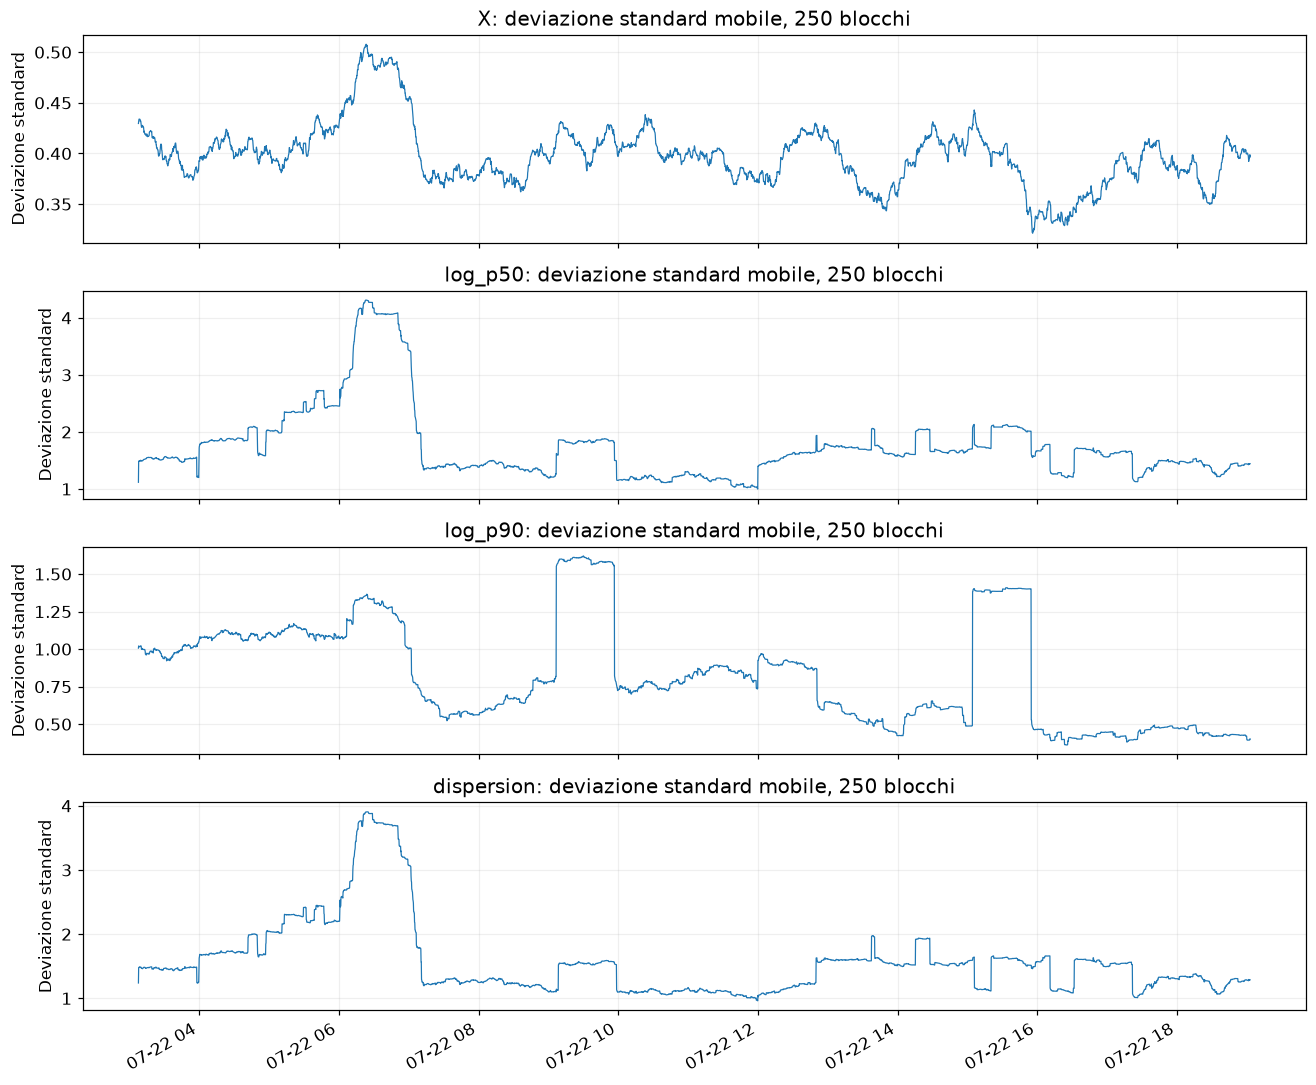

In [5]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, name in zip(axes, variables, strict=True):
    ax.plot(dates, testing[f"residual_{name}"].rolling(250).std(), linewidth=0.8)
    ax.set(title=f"{name}: deviazione standard mobile, 250 blocchi", ylabel="Deviazione standard")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
plt.close(fig)

## 6. Volatilità e stato osservabile precedente

Regrediamo il quadrato dell’innovazione su utilizzo, base fee e priority fee del blocco precedente.
Gli errori HAC rendono il controllo meno sensibile alla dipendenza; il risultato è associativo, non causale.

In [6]:
state_columns = [
    "X",
    "log_base_fee_per_gas",
    "log_effective_priority_fee_per_gas_p50",
    "log_effective_priority_fee_per_gas_p90",
]
lagged_state = df.set_index("block_number")[state_columns].shift(1)
train_states = lagged_state.loc[validation["block_number"]]
test_states = lagged_state.loc[testing["block_number"]]
assert test_states.notna().all().all()
state_mean, state_std = train_states.mean(), train_states.std()
assert (state_std > 0).all()
state_design = sm.add_constant((test_states - state_mean) / state_std).to_numpy()
volatility_rows = []
for name in variables:
    errors = testing[f"residual_{name}"].to_numpy()
    scale = np.mean(validation[f"residual_{name}"].to_numpy() ** 2)
    fit = sm.OLS(errors**2 / scale, state_design).fit(cov_type="HAC", cov_kwds={"maxlags": 50})
    for index, column in enumerate(["intercept", *state_columns]):
        volatility_rows.append(
            {
                "variable": name,
                "predictor": column,
                "coefficient": fit.params[index],
                "HAC_p": fit.pvalues[index],
                "R2": fit.rsquared,
            }
        )
volatility_state = pd.DataFrame(volatility_rows)
display(volatility_state.round(6))
volatility_state.to_csv(output_directory / "volatility_state.csv", index=False)

,variable,predictor,coefficient,HAC_p,R2
0,X,intercept,1.033282,0.000000,0.014624
1,X,X,-0.149653,0.000000,0.014624
2,X,log_base_fee_per_gas,-0.065604,0.010857,0.014624
3,X,log_effective_priority_fee_per_gas_p50,-0.046623,0.226943,0.014624
4,X,log_effective_priority_fee_per_gas_p90,-0.005536,0.866287,0.014624
5,log_p50,intercept,1.417252,0.000000,0.018599
6,log_p50,X,0.142880,0.198215,0.018599
7,log_p50,log_base_fee_per_gas,0.337880,0.060198,0.018599
8,log_p50,log_effective_priority_fee_per_gas_p50,-0.805648,0.035716,0.018599
9,log_p50,log_effective_priority_fee_per_gas_p90,0.012514,0.934036,0.018599


## 7. Clustering della volatilità

Visualizziamo la memoria nei quadrati oltre a riportare ARCH e Ljung–Box.
Autocorrelazioni persistenti motivano modelli della varianza ma non identificano automaticamente regimi latenti.

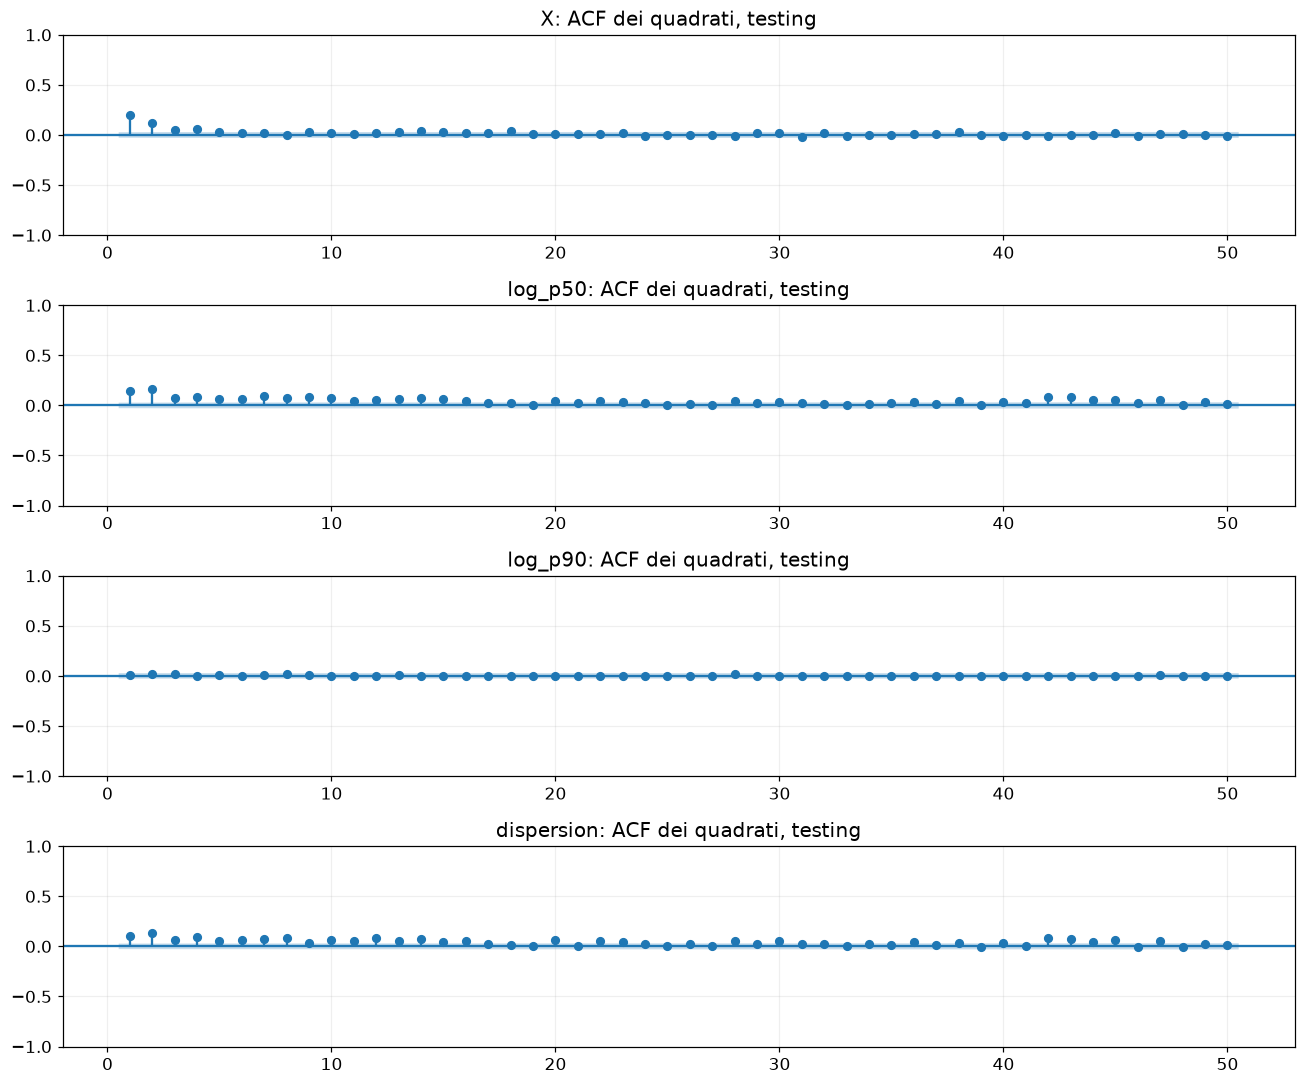

In [7]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(4, 1, figsize=(12, 10))
for ax, name in zip(axes, variables, strict=True):
    plot_acf(
        testing[f"residual_{name}"] ** 2,
        lags=50,
        fft=True,
        zero=False,
        ax=ax,
        title=f"{name}: ACF dei quadrati, testing",
    )
fig.tight_layout()
plt.show()
plt.close(fig)

## 8. GARCH(1,1) e confronto predittivo: confronto fuori campione

Quando ARCH emerge sulla validation, confrontiamo GARCH(1,1) e GJR-GARCH con varianza costante.
I parametri si stimano solo sulla validation; ogni varianza testing si aggiorna usando l’innovazione appena osservata, mai quella futura.

/Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/.venv/lib/python3.11/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
/Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/.venv/lib/python3.11/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result

,variable,model,validation_ARCH10_p,validation_AIC,testing_QLIKE,testing_standardized_LB50_p,persistence,gamma
0,X,constant,0.000000,NaN,1.069367,0.000000,0.000000,NaN
1,X,GARCH,0.000000,14020.303990,1.022847,0.195086,0.548855,NaN
2,X,GJR-GARCH,0.000000,13984.577671,1.011622,0.005328,0.479585,0.213872
3,log_p50,constant,0.001984,NaN,1.274525,0.000000,0.000000,NaN
4,log_p50,GARCH,0.001984,14026.518989,1.111823,0.001537,0.319956,NaN
5,log_p50,GJR-GARCH,0.001984,14006.957108,1.197911,0.000000,0.173348,-0.307485
6,log_p90,constant,0.990578,NaN,0.948004,1.000000,0.000000,NaN
7,dispersion,constant,0.000116,NaN,1.412269,0.000000,0.000000,NaN
8,dispersion,GARCH,0.000116,14077.597363,1.236554,0.559456,0.435925,NaN
9,dispersion,GJR-GARCH,0.000116,14020.794513,1.324655,0.000000,0.332179,0.444455


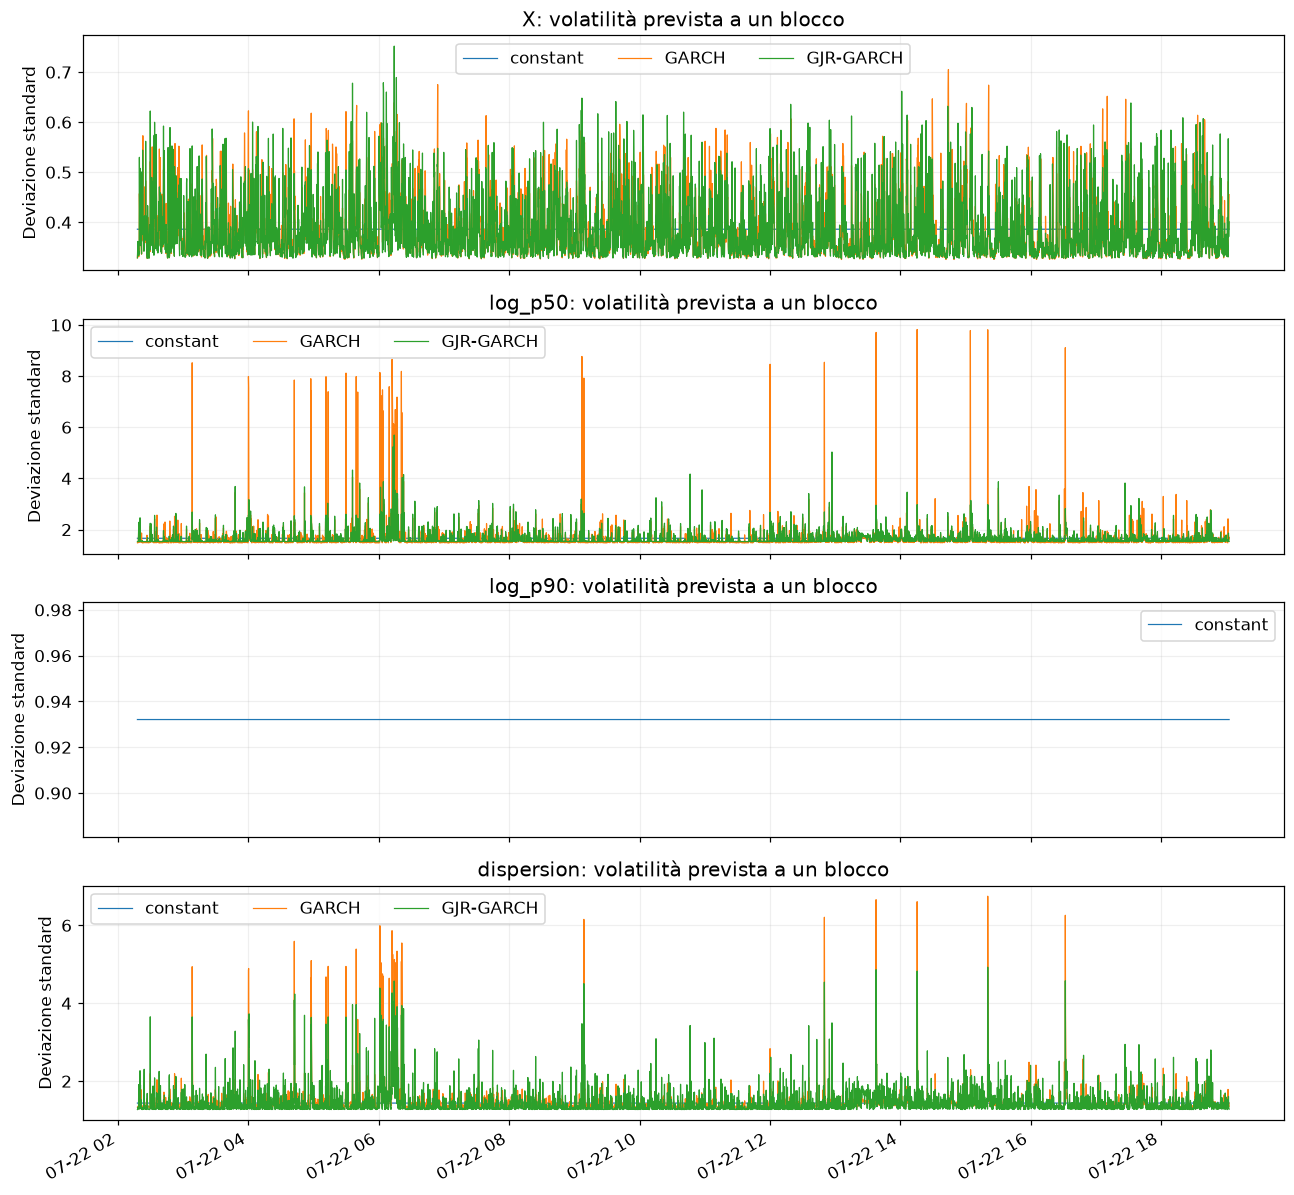

In [8]:
from arch import arch_model


def variance_forecast(parameters, previous_variance, previous_error, errors):
    predicted = []
    for error in errors:
        variance = (
            parameters["omega"]
            + parameters["alpha[1]"] * previous_error**2
            + parameters.get("gamma[1]", 0) * previous_error**2 * (previous_error < 0)
            + parameters["beta[1]"] * previous_variance
        )
        predicted.append(variance)
        previous_variance, previous_error = variance, error
    return np.asarray(predicted)


check_parameters = {"omega": 1, "alpha[1]": 0.1, "beta[1]": 0.5, "gamma[1]": 0.2}
assert np.allclose(variance_forecast(check_parameters, 2, -2, [3, 0]), [3.2, 3.5])
assert np.isclose(variance_forecast(check_parameters, 2, -2, [3, 100])[0], 3.2)
variance_rows = []
variance_predictions = {}
for name in variables:
    train_errors = validation[f"residual_{name}"].to_numpy()
    test_errors = testing[f"residual_{name}"].to_numpy()
    # Una scala fissata prima del testing migliora il condizionamento dell'ottimizzatore.
    scale = train_errors.std()
    assert scale > 0
    train_scaled, test_scaled = train_errors / scale, test_errors / scale
    constant = np.mean(train_scaled**2)
    forecasts = {"constant": np.full(len(test_scaled), constant)}
    fits = {}
    validation_arch_p = het_arch(train_scaled, nlags=10)[1]
    if validation_arch_p < 0.05:
        for label, asymmetry in [("GARCH", 0), ("GJR-GARCH", 1)]:
            fit = arch_model(
                train_scaled,
                mean="Zero",
                vol="GARCH",
                p=1,
                o=asymmetry,
                q=1,
                dist="normal",
                rescale=False,
            ).fit(disp="off")
            if fit.convergence_flag != 0:
                raise RuntimeError(f"Ottimizzatore {label} non convergente per {name}")
            fits[label] = fit
            forecast = variance_forecast(
                fit.params, fit.conditional_volatility[-1] ** 2, train_scaled[-1], test_scaled
            )
            assert np.isfinite(forecast).all() and (forecast > 0).all()
            forecasts[label] = forecast
    for label, forecast in forecasts.items():
        fit = fits.get(label)
        variance_rows.append(
            {
                "variable": name,
                "model": label,
                "validation_ARCH10_p": validation_arch_p,
                "validation_AIC": fit.aic if fit is not None else np.nan,
                "testing_QLIKE": np.mean(np.log(forecast) + test_scaled**2 / forecast),
                "testing_standardized_LB50_p": acorr_ljungbox(
                    test_scaled**2 / forecast, lags=[50], return_df=True
                )["lb_pvalue"].iloc[0],
                "persistence": (
                    fit.params["alpha[1]"]
                    + fit.params["beta[1]"]
                    + 0.5 * fit.params.get("gamma[1]", 0)
                )
                if fit is not None
                else 0,
                "gamma": fit.params.get("gamma[1]", np.nan) if fit is not None else np.nan,
            }
        )
        variance_predictions[name, label] = forecast * scale**2
variance_comparison = pd.DataFrame(variance_rows)
display(variance_comparison.round(6))
variance_comparison.to_csv(output_directory / "variance_models.csv", index=False)
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
for ax, name in zip(axes, variables, strict=True):
    for (variable, label), forecast in variance_predictions.items():
        if variable == name:
            ax.plot(dates, np.sqrt(forecast), label=label, linewidth=0.8)
    ax.set(title=f"{name}: volatilità prevista a un blocco", ylabel="Deviazione standard")
    ax.legend(ncols=3)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
plt.close(fig)

## 9. Asimmetria: GJR-GARCH

Confrontiamo la risposta della volatilità a innovazioni di segno negativo con quella simmetrica.
GJR è l’alternativa asimmetrica esaminata; un QLIKE inferiore sul testing indica un vantaggio predittivo osservato.

In [9]:
display(
    variance_comparison.query("model == 'GJR-GARCH'")[
        ["variable", "gamma", "persistence", "testing_QLIKE", "testing_standardized_LB50_p"]
    ]
)
display(variance_comparison.pivot(index="variable", columns="model", values="testing_QLIKE"))

,variable,gamma,persistence,testing_QLIKE,testing_standardized_LB50_p
2,X,0.213872,0.479585,1.011622,5.327815e-03
5,log_p50,-0.307485,0.173348,1.197911,2.750530e-39
9,dispersion,0.444455,0.332179,1.324655,4.918544e-09


model,GARCH,GJR-GARCH,constant
variable,,,
X,1.022847,1.011622,1.069367
dispersion,1.236554,1.324655,1.412269
log_p50,1.111823,1.197911,1.274525
log_p90,NaN,NaN,0.948004


## 10. Volatilità dipendente dalla congestione

Confrontiamo la varianza delle innovazioni tra stato precedente ordinario e congestione alta.
La soglia q90 viene dalla validation: le fasce sono osservabili, mentre un regime latente richiederebbe evidenza ulteriore.

In [10]:
# Fasce fissate sulla validation, senza usare lo stato contemporaneo del target.
cutoff = train_states["X"].quantile(0.9)
congestion = np.where(test_states["X"] >= cutoff, "alta (soglia validation q90)", "ordinaria")
regime_rows = []
for name in variables:
    for regime in np.unique(congestion):
        values = testing.loc[congestion == regime, f"residual_{name}"]
        regime_rows.append(
            {
                "variable": name,
                "previous_utilization": regime,
                "n": len(values),
                "mean_squared_error": (values**2).mean(),
            }
        )
regime_variance = pd.DataFrame(regime_rows)
display(regime_variance)
regime_variance.to_csv(output_directory / "congestion_variance.csv", index=False)

,variable,previous_utilization,n,mean_squared_error
0,X,alta (soglia validation q90),557,0.190538
1,X,ordinaria,4443,0.155459
2,log_p50,alta (soglia validation q90),557,6.982672
3,log_p50,ordinaria,4443,3.059085
4,log_p90,alta (soglia validation q90),557,1.020596
5,log_p90,ordinaria,4443,0.793451
6,dispersion,alta (soglia validation q90),557,5.751519
7,dispersion,ordinaria,4443,2.557572


## 11. Quali estensioni sono supportate?

Affianchiamo significatività del clustering e punteggi fuori campione della varianza.
I confronti sono diagnostici, senza correzione multipla; una media ancora incompleta può contribuire ai segnali ARCH.

In [11]:
display(arch_tests.query("lag == 10")[["variable", "LM_p"]])
display(squared_tests.query("lag == 50")[["variable", "lb_pvalue"]])
display(
    variance_comparison[
        ["variable", "model", "testing_QLIKE", "persistence", "testing_standardized_LB50_p"]
    ]
)
print(
    "GJR esamina l’asimmetria. EGARCH e regimi latenti restano ipotesi "
    "da verificare su altri periodi, non estensioni automatiche."
)

,variable,LM_p
1,X,7.220258e-47
5,log_p50,1.051079e-52
9,log_p90,9.268452e-01
13,dispersion,4.170994e-37


,variable,lb_pvalue
3,X,3.257705e-50
7,log_p50,1.561386e-131
11,log_p90,1.000000e+00
15,dispersion,3.605530e-105


,variable,model,testing_QLIKE,persistence,testing_standardized_LB50_p
0,X,constant,1.069367,0.000000,3.257705e-50
1,X,GARCH,1.022847,0.548855,1.950861e-01
2,X,GJR-GARCH,1.011622,0.479585,5.327815e-03
3,log_p50,constant,1.274525,0.000000,1.561386e-131
4,log_p50,GARCH,1.111823,0.319956,1.536882e-03
5,log_p50,GJR-GARCH,1.197911,0.173348,2.750530e-39
6,log_p90,constant,0.948004,0.000000,1.000000e+00
7,dispersion,constant,1.412269,0.000000,3.605530e-105
8,dispersion,GARCH,1.236554,0.435925,5.594562e-01
9,dispersion,GJR-GARCH,1.324655,0.332179,4.918544e-09


GJR esamina l’asimmetria. EGARCH e regimi latenti restano ipotesi da verificare su altri periodi, non estensioni automatiche.
